## SWE 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from functools import partial
from ipywidgets import interact, IntSlider, fixed

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))

from the_well.data import WellDataset
from the_well.utils.download import well_download

from helpers import to_numpy, plot_sensors_on_field, run_experiment as run_experiment_base

## Solver / Data

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ERRORS = []

# Hyperparameters 
LAGS = 50
COMPRESS = 80
TRAIN_SIZE = 0.8
VAL_SIZE = 0.1
TEST_SIZE = 0.1

OPTIMIZER = "AdamW"
LEARNING_RATE = 1e-3
NUM_EPOCHS = 400
BATCH_SIZE = 64
PATIENCE = 100
VERBOSE_TRAIN = True

LR_SCHEDULER = "CosineAnnealingLR"
SCHEDULER_STEP_SIZE = NUM_EPOCHS

TR_ENCODER_DEPTH = 2
TR_N_HEADS = 4
TR_DIM_FEEDFORWARD = 128
TR_HIDDEN_SIZE = 64
TR_DROPOUT = 0.0

LSTM_NUM_LAYERS = 2
GRUD_HIDDEN_SIZE = 64
GRUD_DROPOUT = 0.0

In [4]:
# Uncomment once if the dataset is missing locally.
# well_download(base_path="", dataset="planetswe", split="train")
# well_download(base_path="", dataset="planetswe", split="valid")
# well_download(base_path="", dataset="planetswe", split="test")

In [5]:
# Load one SWE trajectory 
dataset = WellDataset(
    well_base_path="datasets",
    well_dataset_name="planetswe",
    well_split_name="train",
    n_steps_input=1008,
    n_steps_output=0,
    use_normalization=False,
)

ntraj = 1
sample0 = dataset[0]
ntimes, Lx, Ly, nfields = sample0["input_fields"].shape
nstate = Lx * Ly 

print("ntimes:", ntimes, "\nLx:", Lx, "\tLy:", Ly, "\nnstate:", nstate)

H       = torch.zeros((ntraj, ntimes, nstate))
U_phi   = torch.zeros((ntraj, ntimes, nstate))
U_theta = torch.zeros((ntraj, ntimes, nstate))

for i in range(ntraj):
    sample = dataset[i]
    H[i]        = sample["input_fields"][:, :, :, 0].reshape(ntimes, nstate)
    U_phi[i]    = sample["input_fields"][:, :, :, 1].reshape(ntimes, nstate)
    U_theta[i]  = sample["input_fields"][:, :, :, 2].reshape(ntimes, nstate)
    del sample

print("H shape:\t", H.shape)
print("Utheta shape:\t", U_theta.shape)
print("Uphi shape:\t", U_phi.shape)

del dataset

ntimes: 1008 
Lx: 256 	Ly: 512 
nstate: 131072
H shape:	 torch.Size([1, 1008, 131072])
Utheta shape:	 torch.Size([1, 1008, 131072])
Uphi shape:	 torch.Size([1, 1008, 131072])


In [10]:
H       = H.reshape(ntimes,nstate).cpu().numpy()
U_phi   = U_phi.reshape(ntimes,nstate).cpu().numpy()
U_theta = U_theta.reshape(ntimes,nstate).cpu().numpy()

## Sensors

In [11]:
# Sensor extraction from the height field
NSENSORS = 3
sensor_flat_idx = np.random.choice(nstate, size=NSENSORS, replace=False)
sensor_rc = np.array(np.unravel_index(sensor_flat_idx, (Lx, Ly))).T

measurements_clean = H[:, sensor_flat_idx]  # (ntimes, nsensors)
measurements = measurements_clean.copy()      # avoid mutating H through a view

# Create DGF-like missingness patterns
idx_short_broken = [1]
idx_long_broken = [2]

t0, t1 = int(0.2 * ntimes), int(0.65 * ntimes)
for j in idx_long_broken:
    measurements[t0:t1, j] = np.nan

for j in idx_short_broken:
    starts = np.random.choice(ntimes - 20, size=10, replace=False)
    for s in starts:
        measurements[s:s+20, j] = np.nan

# Always-available subset
mask_available = ~np.isnan(measurements).any(axis=0)
measurements_av = measurements[:, mask_available]

print("All sensors:", np.arange(NSENSORS))
print("Always available sensors:", np.where(mask_available)[0])
print("measurements shape:", measurements.shape)
print("measurements_av shape:", measurements_av.shape)

All sensors: [0 1 2]
Always available sensors: [0]
measurements shape: (1008, 3)
measurements_av shape: (1008, 1)


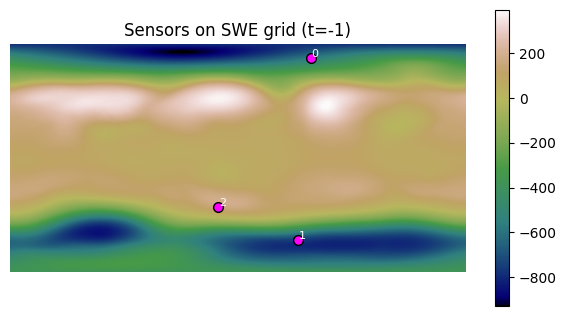

In [12]:
plot_sensors_on_field(
    H=H,
    Lx=Lx,
    Ly=Ly,
    NSENSORS=NSENSORS,
    sensor_rc=sensor_rc,
    time_idx=-1,
)

## Experiment Helpers

In [14]:
# Configure helper-based experiment function with SWE context
run_experiment = partial(
    run_experiment_base,
    H=H,
    Utheta=U_theta,
    Uphi=U_phi,
    device=device,
    ERRORS=ERRORS,
    Lx=Lx,
    Ly=Ly,
    LAGS=LAGS,
    TRAIN_SIZE=TRAIN_SIZE,
    VAL_SIZE=VAL_SIZE,
    TEST_SIZE=TEST_SIZE,
    COMPRESS=COMPRESS,
    OPTIMIZER=OPTIMIZER,
    LEARNING_RATE=LEARNING_RATE,
    NUM_EPOCHS=NUM_EPOCHS,
    BATCH_SIZE=BATCH_SIZE,
    PATIENCE=PATIENCE,
    VERBOSE_TRAIN=VERBOSE_TRAIN,
    LR_SCHEDULER=LR_SCHEDULER,
    SCHEDULER_STEP_SIZE=SCHEDULER_STEP_SIZE,
    TR_ENCODER_DEPTH=TR_ENCODER_DEPTH,
    TR_N_HEADS=TR_N_HEADS,
    TR_DIM_FEEDFORWARD=TR_DIM_FEEDFORWARD,
    TR_HIDDEN_SIZE=TR_HIDDEN_SIZE,
    TR_DROPOUT=TR_DROPOUT,
    LSTM_NUM_LAYERS=LSTM_NUM_LAYERS,
    GRUD_HIDDEN_SIZE=GRUD_HIDDEN_SIZE,
    GRUD_DROPOUT=GRUD_DROPOUT,
)

In [ ]:
# run_experiment is imported from helpers.py and configured in the previous cell.
# Re-run the previous cell if you change hyperparameters or data variables.

## (T.0) only available sensors

Nuber of nan values in measurements after imputation: 0 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 50, 1]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 1]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 1]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  25%|██▌       | 101/400 [00:31<01:34,  3.17it/s, Train Loss=0.02563, Val Loss=1.40251, Patience=99, Best Val Loss=1.39625, LR=8.48e-04]

Early stopping at epoch 102
Training completed with best validation loss: 1.3962


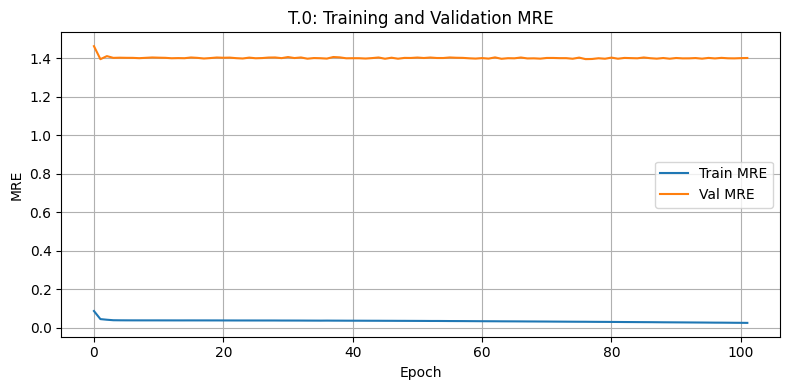

[T.0] test MRE: 0.96301

 ---------------------------------------------------------------------------------------------------- 



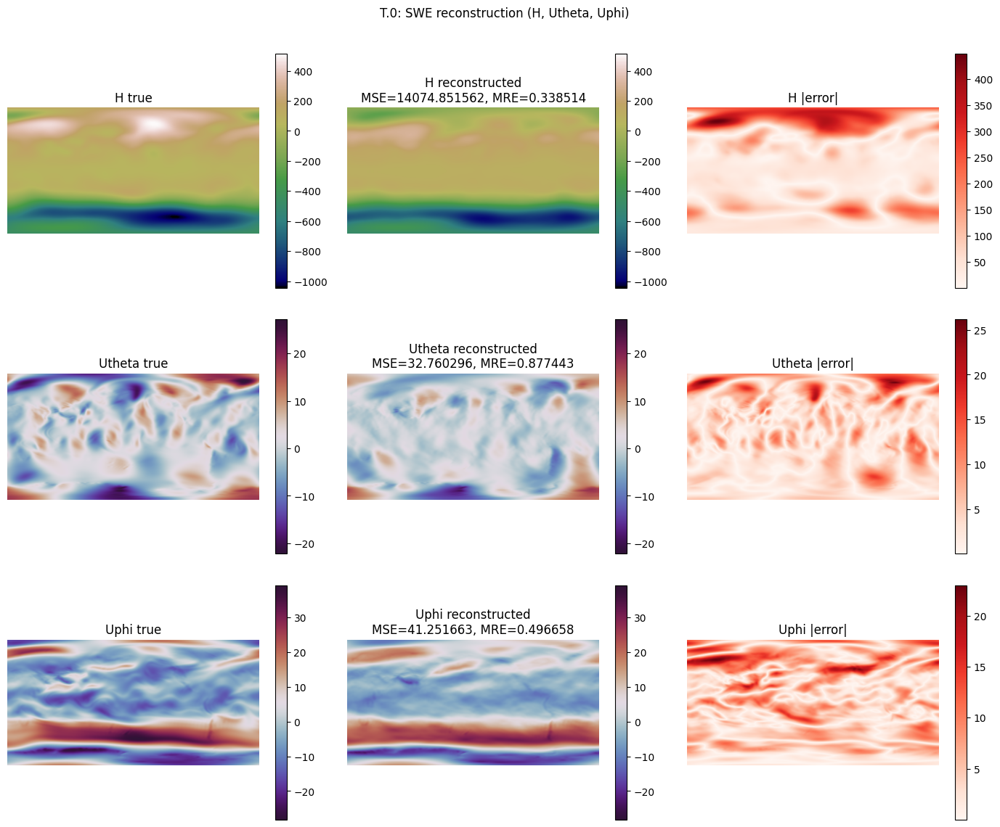

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): transformer + MLP,(T.0) only available sensors,0.045276,1.396247,2.863958,0.418882,0.904218,0.963014


In [ ]:
df_errors = run_experiment("T.0", "(T.0) only available sensors", measurements_av, "transformer")
display(df_errors)
df_errors.to_csv("dataframe_errors.csv", index=False)

## (S.0) only available sensors

Nuber of nan values in measurements after imputation: 0 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 50, 1]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 1]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 1]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  45%|████▌     | 180/400 [00:56<01:08,  3.20it/s, Train Loss=0.02025, Val Loss=1.40709, Patience=99, Best Val Loss=1.39753, LR=5.74e-04]


Early stopping at epoch 181
Training completed with best validation loss: 1.3975


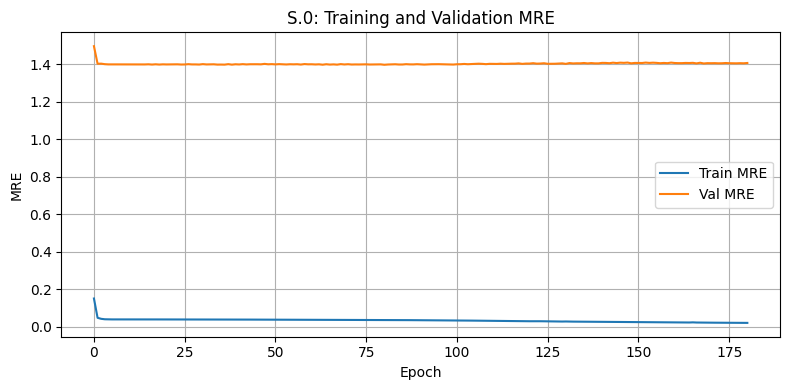

[S.0] test MRE: 0.96358

 ---------------------------------------------------------------------------------------------------- 



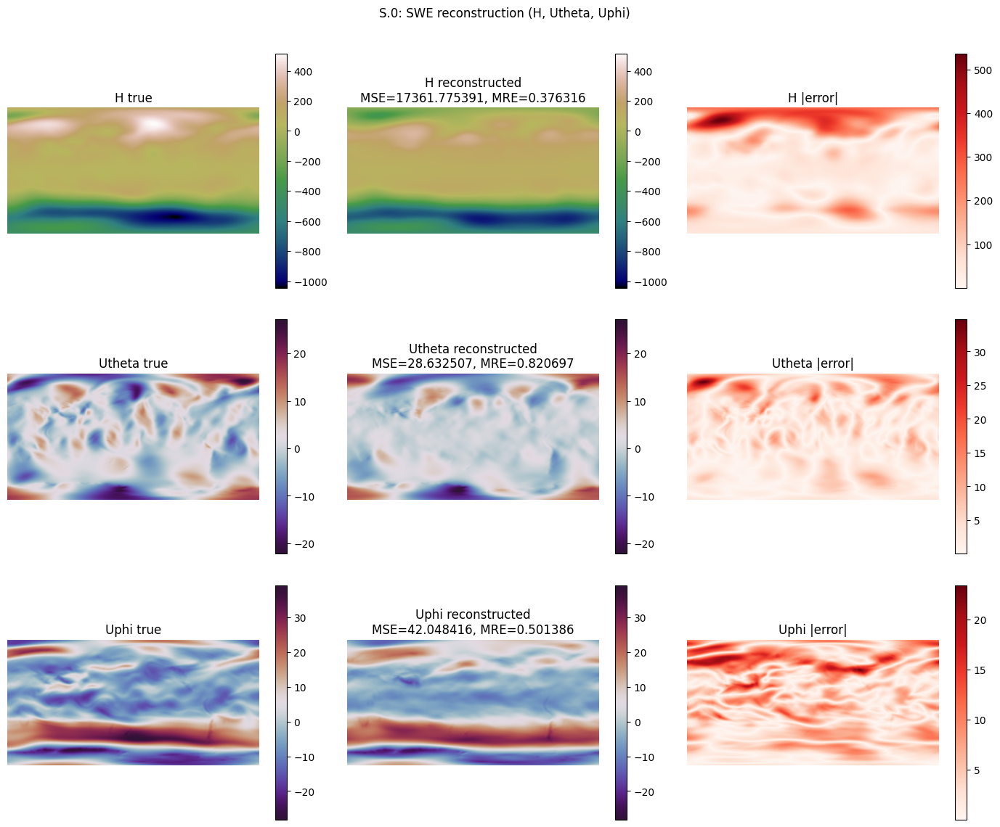

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
1,(mSHRED): lstm + MLP,(S.0) only available sensors,0.03558,1.397534,2.842296,0.370623,0.903067,0.963581


In [ ]:
df_errors = run_experiment("S.0", "(S.0) only available sensors", measurements_av, "lstm")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.1.A): Median imputer

Nuber of nan values in measurements after imputation: 0 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  38%|███▊      | 153/400 [01:17<02:04,  1.98it/s, Train Loss=0.01210, Val Loss=1.42713, Patience=99, Best Val Loss=1.38149, LR=6.77e-04]

Early stopping at epoch 154
Training completed with best validation loss: 1.3815


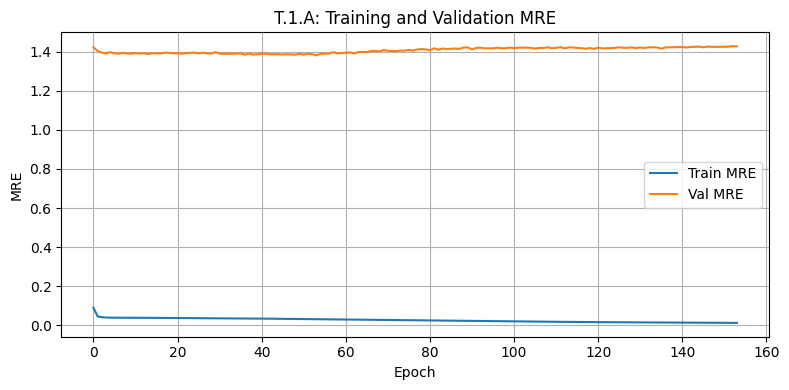

[T.1.A] test MRE: 0.96809

 ---------------------------------------------------------------------------------------------------- 



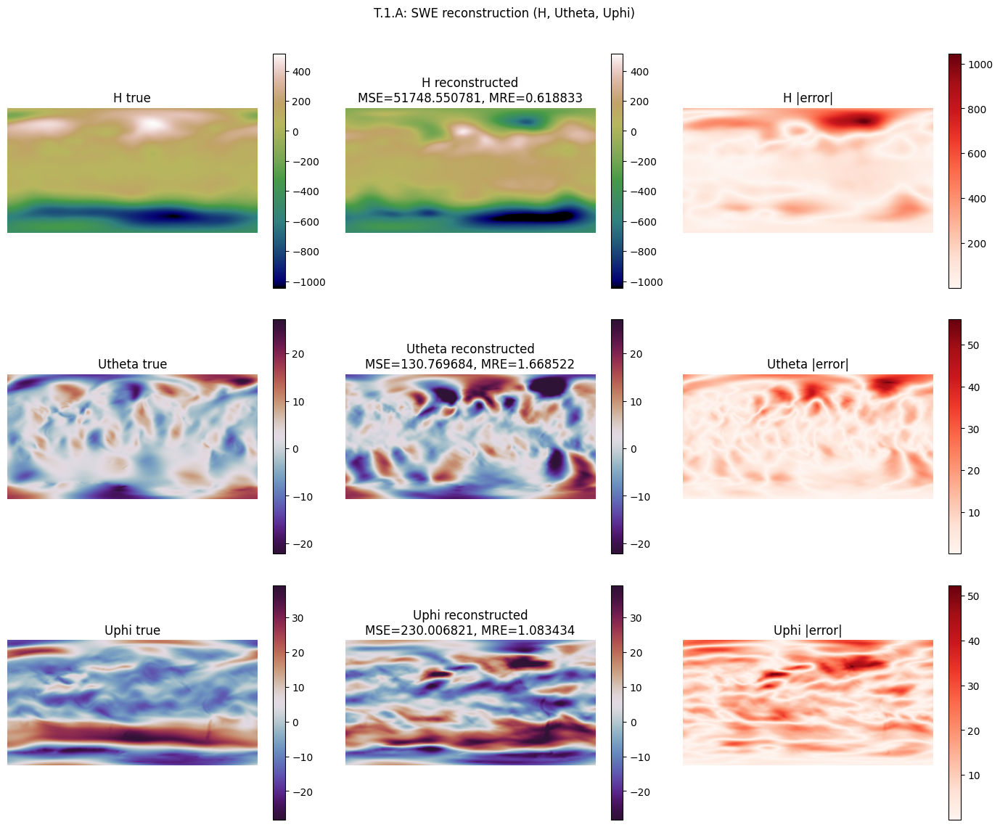

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
2,(mSHRED): transformer + MLP,(T.1.A) median imputer,0.031032,1.381489,2.854257,0.346627,0.897385,0.968088


In [ ]:
df_errors = run_experiment("T.1.A", "(T.1.A) median imputer", measurements, "transformer", imputer="median")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (S.1.A): Median imputer

Nuber of nan values in measurements after imputation: 0 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  50%|█████     | 202/400 [00:56<00:55,  3.55it/s, Train Loss=0.01104, Val Loss=1.39989, Patience=99, Best Val Loss=1.38826, LR=4.88e-04]

Early stopping at epoch 203
Training completed with best validation loss: 1.3883


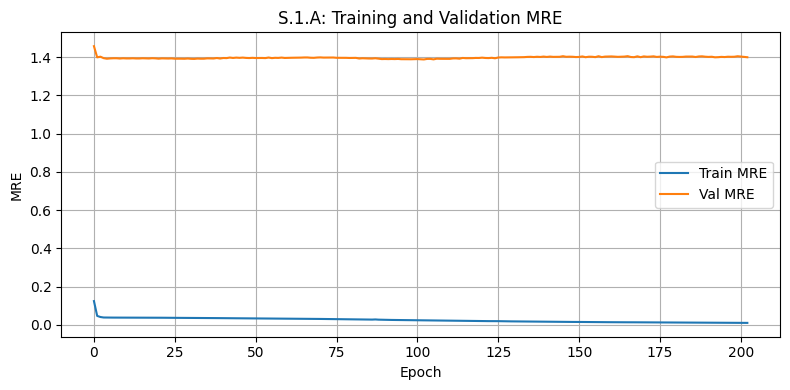

[S.1.A] test MRE: 0.96648

 ---------------------------------------------------------------------------------------------------- 



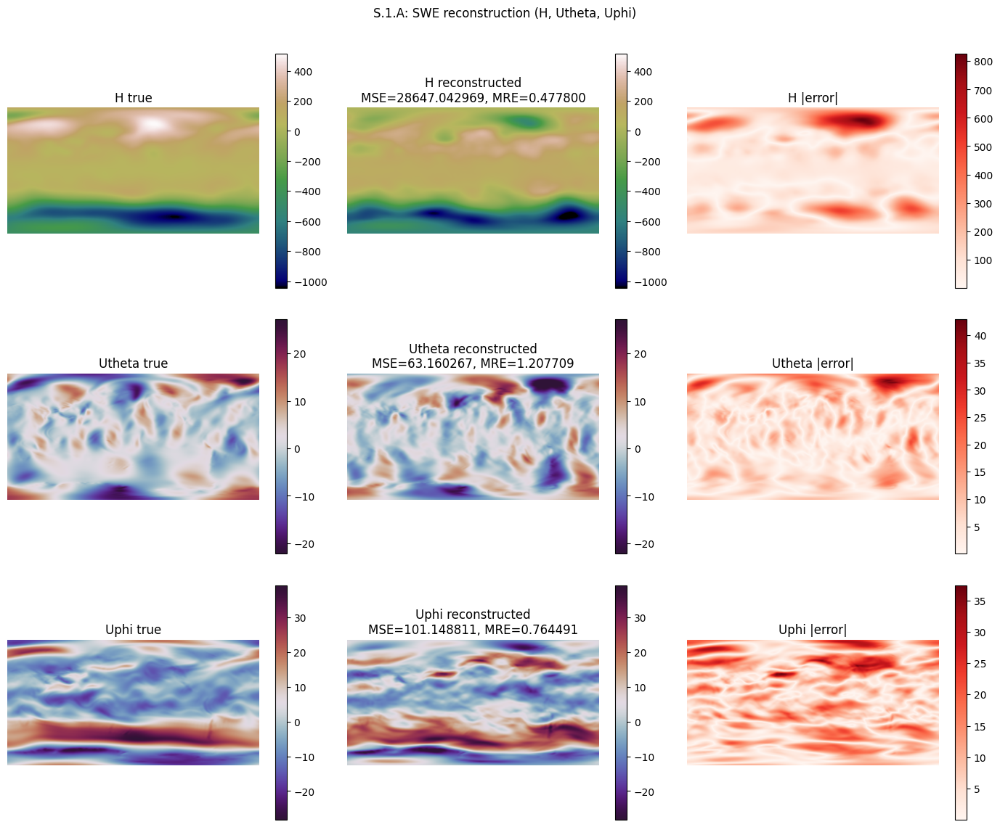

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
3,(mSHRED): lstm + MLP,(S.1.A) median imputer,0.024276,1.388257,2.848928,0.304609,0.90183,0.966478


In [ ]:
df_errors = run_experiment("S.1.A", "(S.1.A) median imputer", measurements, "lstm", imputer="median")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.1.B): Mean imputer

Nuber of nan values in measurements after imputation: 0 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  40%|████      | 162/400 [00:51<01:15,  3.16it/s, Train Loss=0.01159, Val Loss=1.41474, Patience=99, Best Val Loss=1.38929, LR=6.43e-04]

Early stopping at epoch 163
Training completed with best validation loss: 1.3893


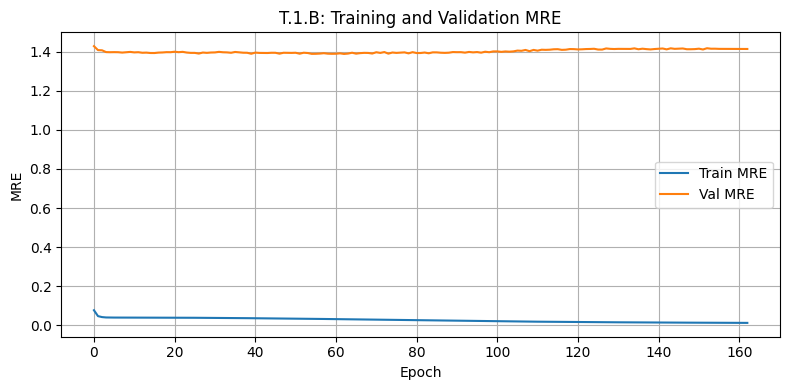

[T.1.B] test MRE: 0.97607

 ---------------------------------------------------------------------------------------------------- 



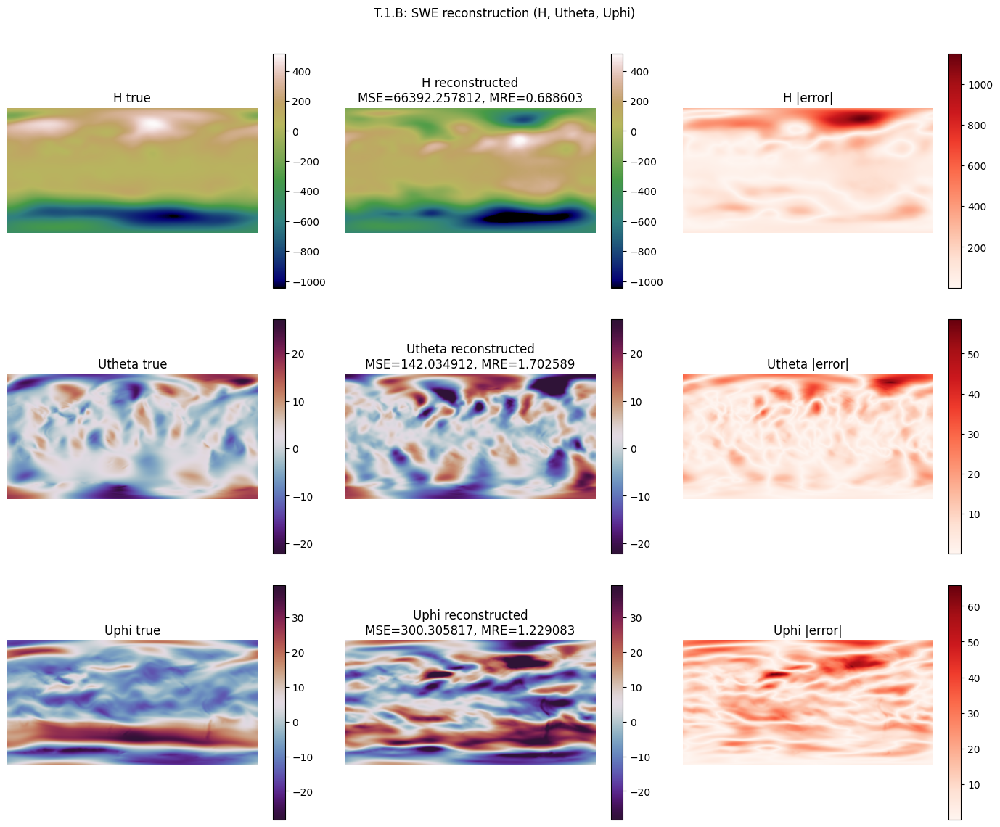

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
4,(mSHRED): transformer + MLP,(T.1.B) mean imputer,0.030449,1.389292,2.940617,0.343266,0.899182,0.97607


In [ ]:
df_errors = run_experiment("T.1.B", "(T.1.B) mean imputer", measurements, "transformer", imputer="mean")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (S.1.B): Mean imputer

Nuber of nan values in measurements after imputation: 0 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  47%|████▋     | 189/400 [00:49<00:55,  3.81it/s, Train Loss=0.01074, Val Loss=1.41013, Patience=99, Best Val Loss=1.38169, LR=5.39e-04]


Early stopping at epoch 190
Training completed with best validation loss: 1.3817


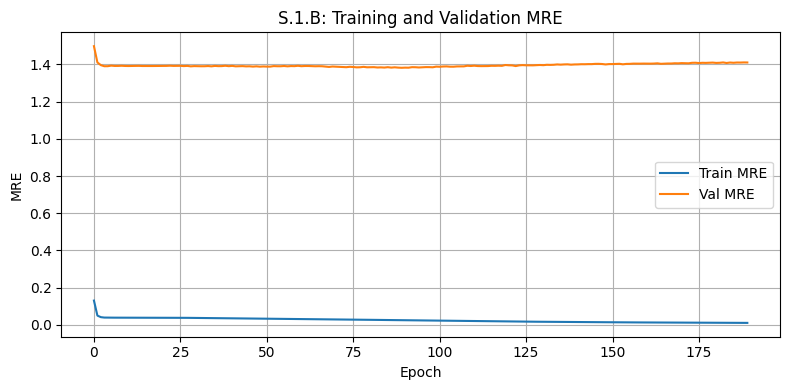

[S.1.B] test MRE: 0.95558

 ---------------------------------------------------------------------------------------------------- 



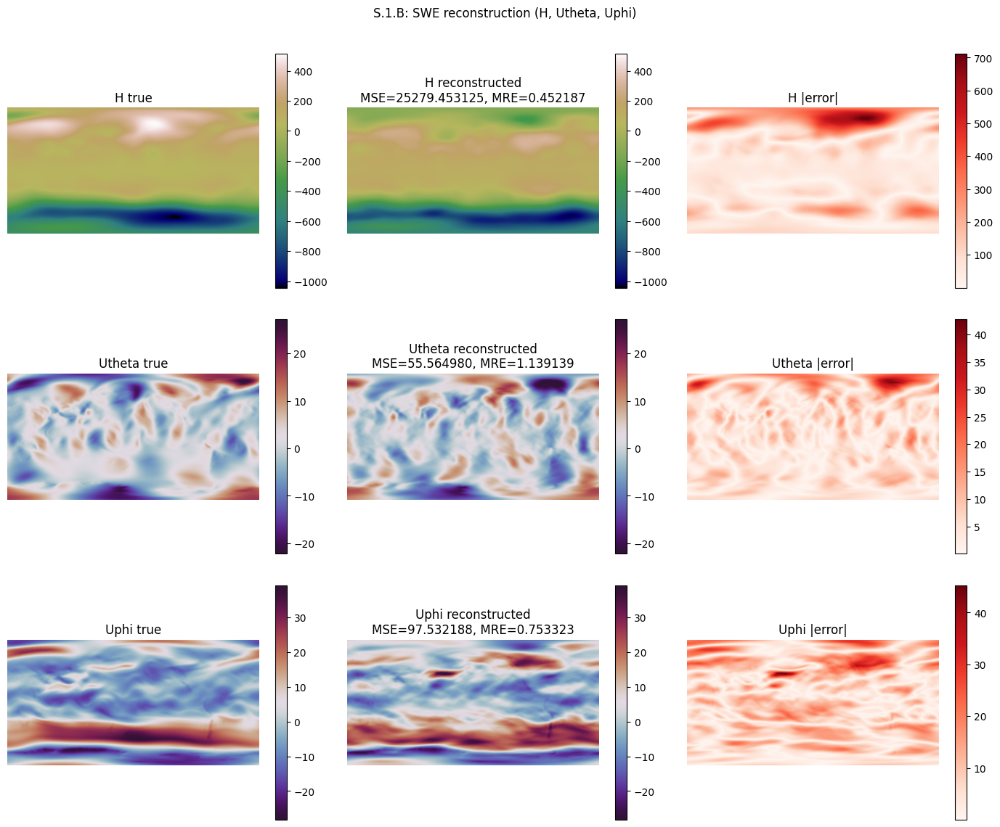

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
5,(mSHRED): lstm + MLP,(S.1.B) mean imputer,0.025283,1.381693,2.877826,0.312148,0.892225,0.955581


In [ ]:
df_errors = run_experiment("S.1.B", "(S.1.B) mean imputer", measurements, "lstm", imputer="mean")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.1.C): Last value imputer

Nuber of nan values in measurements after imputation: 0 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  49%|████▉     | 195/400 [01:17<01:21,  2.51it/s, Train Loss=0.01033, Val Loss=1.40782, Patience=99, Best Val Loss=1.40298, LR=5.16e-04]

Early stopping at epoch 196
Training completed with best validation loss: 1.4030


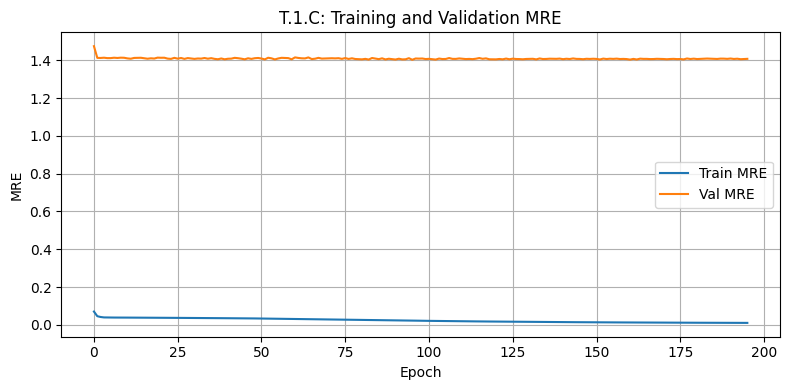

[T.1.C] test MRE: 0.98273

 ---------------------------------------------------------------------------------------------------- 



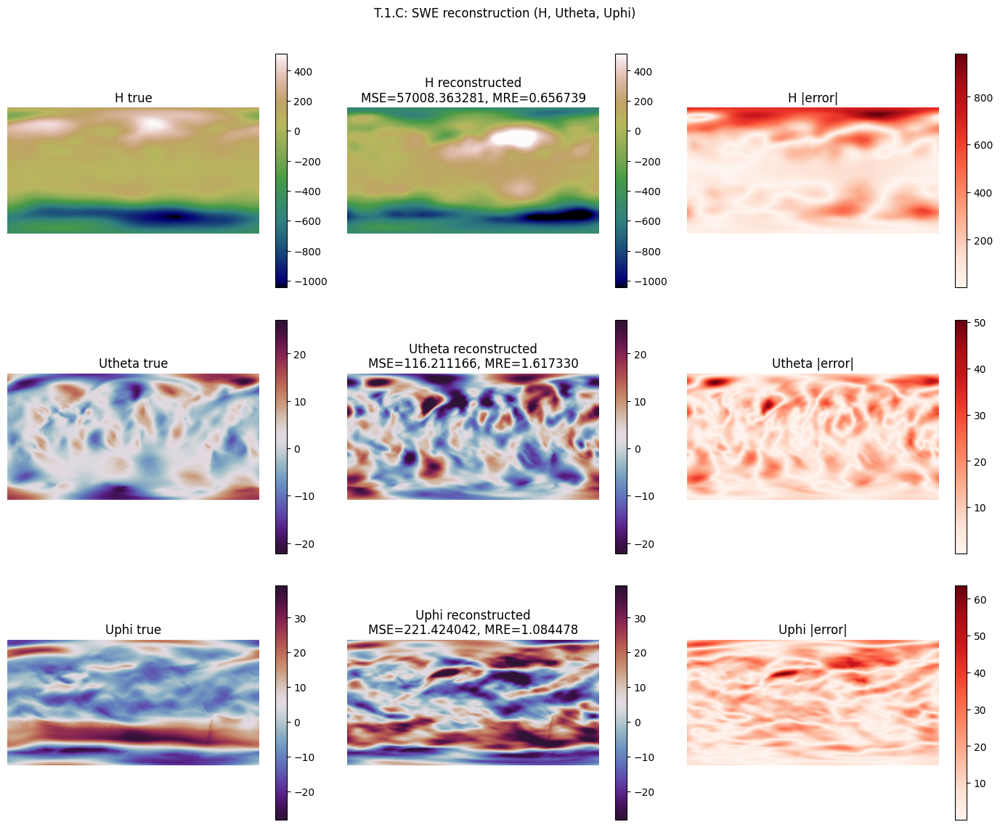

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
6,(mSHRED): transformer + MLP,(T.1.C) last value imputer,0.02239,1.402983,3.008563,0.293765,0.899032,0.982732


In [ ]:
df_errors = run_experiment("T.1.C", "(T.1.C) last value imputer", measurements, "transformer", imputer="last_value")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (S.1.C): Last value imputer

Nuber of nan values in measurements after imputation: 0 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  25%|██▌       | 101/400 [00:46<02:16,  2.20it/s, Train Loss=0.02258, Val Loss=1.39624, Patience=99, Best Val Loss=1.39084, LR=8.48e-04]

Early stopping at epoch 102
Training completed with best validation loss: 1.3908


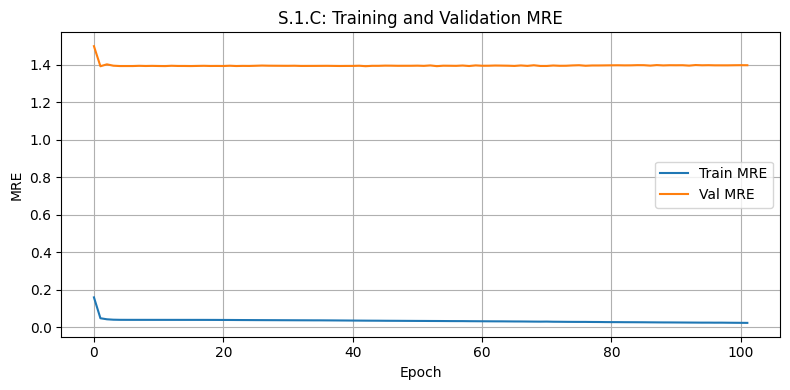

[S.1.C] test MRE: 0.95565

 ---------------------------------------------------------------------------------------------------- 



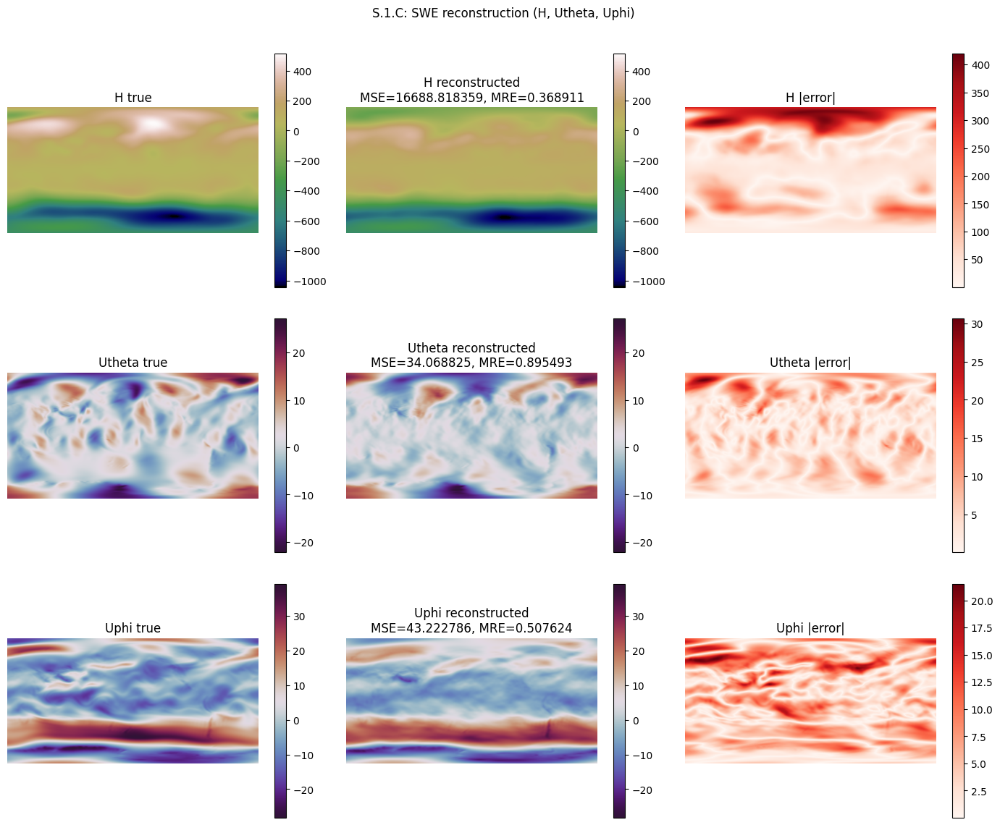

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
7,(mSHRED): lstm + MLP,(S.1.C) last value imputer,0.047366,1.39084,2.84276,0.428099,0.897367,0.955647


In [ ]:
df_errors = run_experiment("S.1.C", "(S.1.C) last value imputer", measurements, "lstm", imputer="last_value")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.2.A): GRUD

Nuber of nan values in measurements after imputation: 649 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 4, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 4, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 4, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  37%|███▋      | 148/400 [03:38<06:12,  1.48s/it, Train Loss=0.01974, Val Loss=1.40556, Patience=99, Best Val Loss=1.38763, LR=6.95e-04]

Early stopping at epoch 149
Training completed with best validation loss: 1.3876


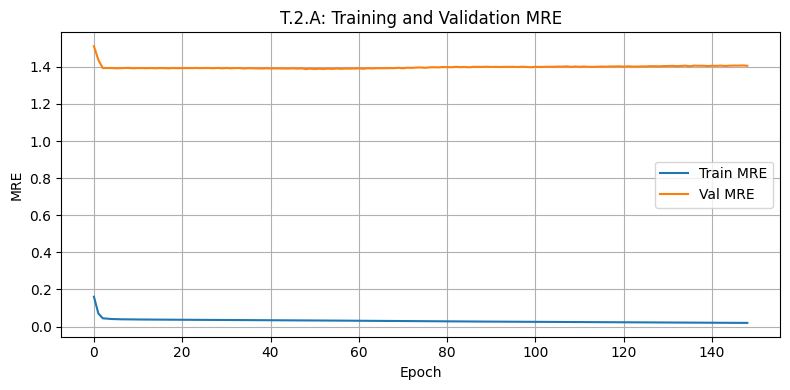

[T.2.A] test MRE: 0.96539

 ---------------------------------------------------------------------------------------------------- 



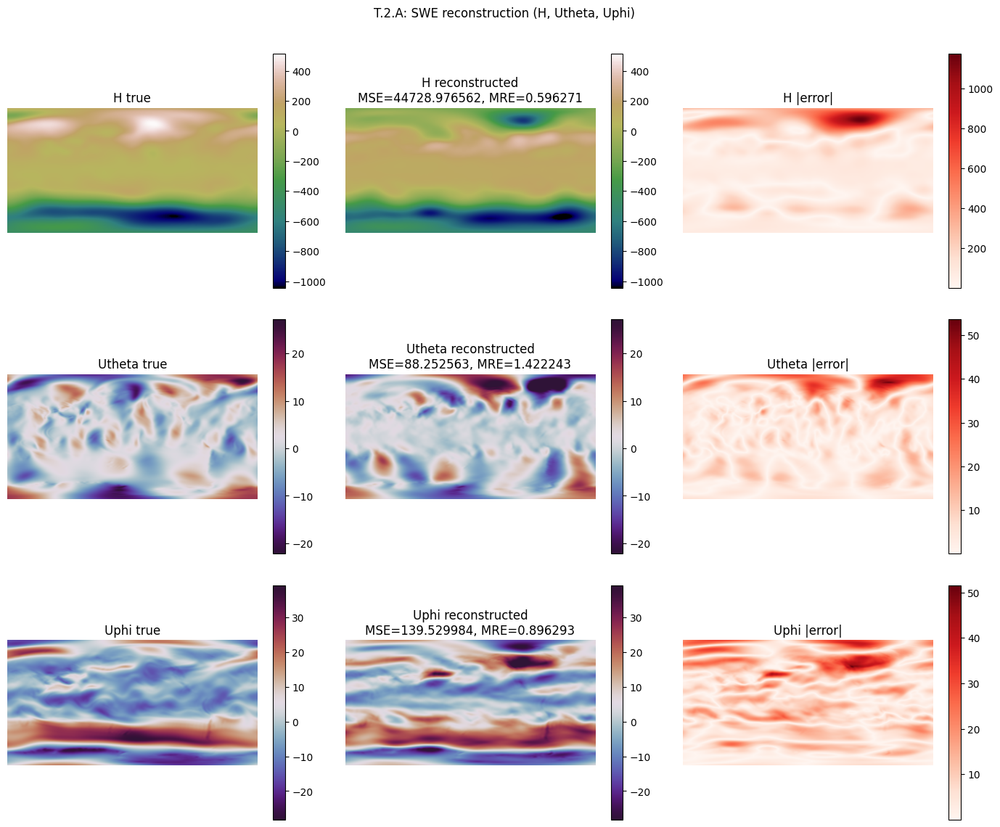

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
8,(mSHRED): grud + MLP,(T.2.A) GRUD encoder,0.032987,1.38763,2.828457,0.357032,0.899134,0.965392


In [ ]:
df_errors = run_experiment("T.2.A", "(T.2.A) GRUD encoder", measurements, "grud", masking_type="grud")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.2.B): Attn-GRUD

Nuber of nan values in measurements after imputation: 649 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([806, 4, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 4, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 4, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  38%|███▊      | 150/400 [02:30<04:10,  1.00s/it, Train Loss=0.01871, Val Loss=1.40226, Patience=99, Best Val Loss=1.39645, LR=6.88e-04]

Early stopping at epoch 151
Training completed with best validation loss: 1.3965


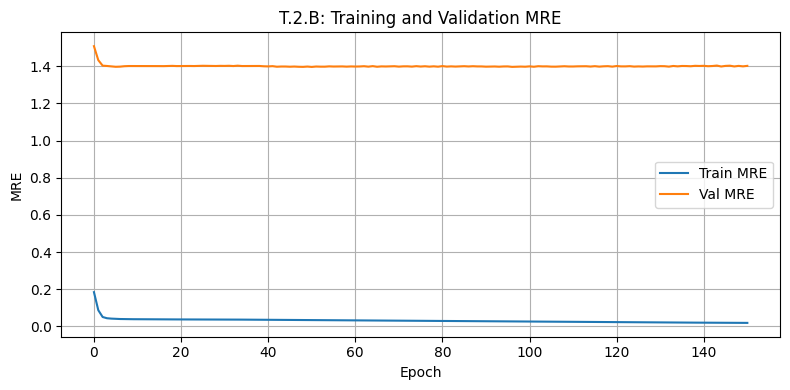

[T.2.B] test MRE: 0.96565

 ---------------------------------------------------------------------------------------------------- 



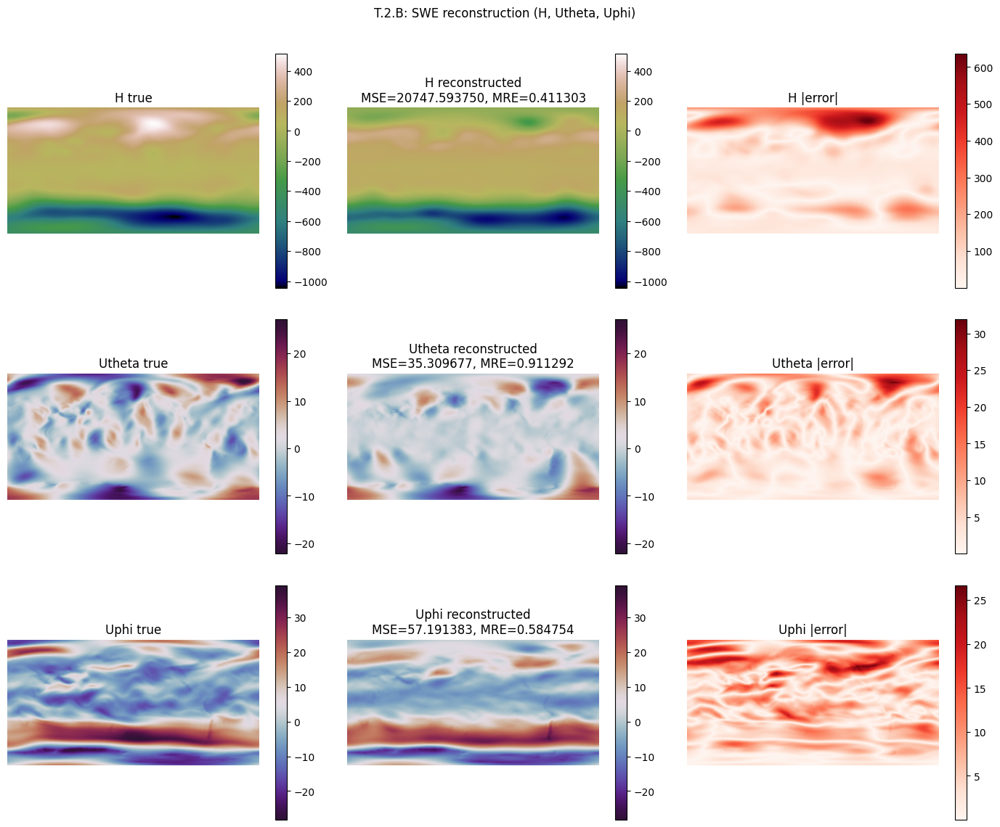

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
9,(mSHRED): att_grud + MLP,(T.2.B) Attention GRUD encoder,0.033942,1.39645,2.909752,0.362277,0.901852,0.965653


In [ ]:
df_errors = run_experiment("T.2.B", "(T.2.B) Attention GRUD encoder", measurements, "att_grud", masking_type="grud")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.3.A): Masking

Nuber of nan values in measurements after imputation: 649 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 649

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  26%|██▌       | 103/400 [00:46<02:14,  2.21it/s, Train Loss=0.01778, Val Loss=1.40091, Patience=99, Best Val Loss=1.38750, LR=8.42e-04]

Early stopping at epoch 104
Training completed with best validation loss: 1.3875


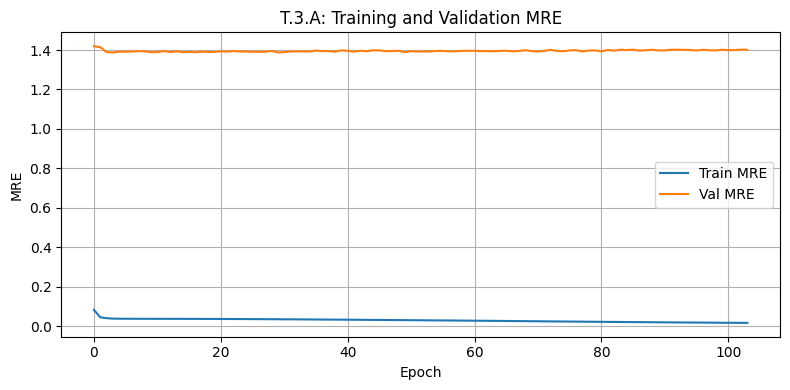

[T.3.A] test MRE: 0.96383

 ---------------------------------------------------------------------------------------------------- 



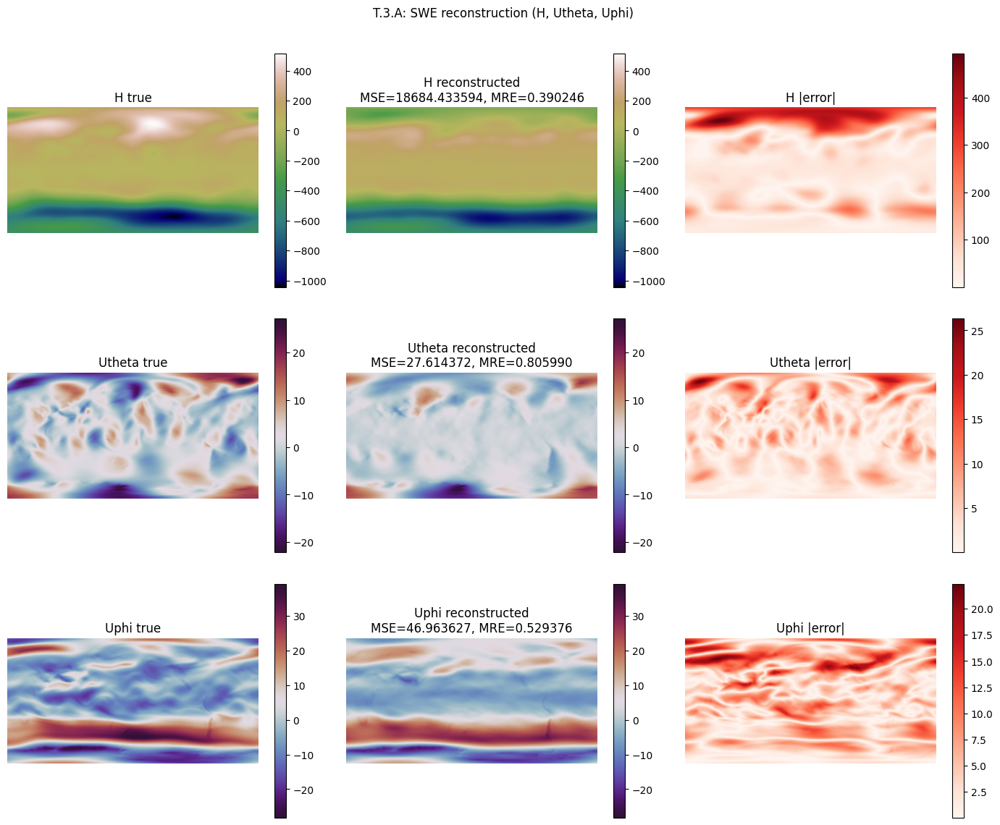

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
10,(mSHRED): transformer + MLP,(T.3.A) masking data,0.039439,1.387496,2.856586,0.390973,0.902601,0.963833


In [ ]:
df_errors = run_experiment("T.3.A", "(T.3.A) masking data", measurements, "transformer", masking_type="mask_data")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.3.B): Masking x2 channels

Nuber of nan values in measurements after imputation: 649 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 649

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  40%|████      | 162/400 [00:48<01:10,  3.37it/s, Train Loss=0.01163, Val Loss=1.38809, Patience=99, Best Val Loss=1.38239, LR=6.43e-04]

Early stopping at epoch 163
Training completed with best validation loss: 1.3824


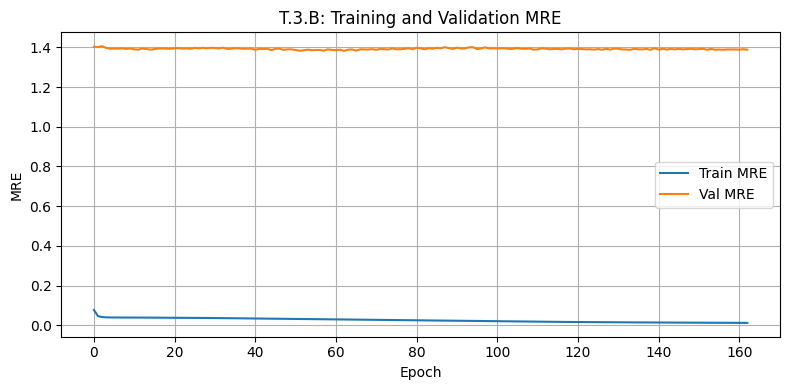

[T.3.B] test MRE: 0.97059

 ---------------------------------------------------------------------------------------------------- 



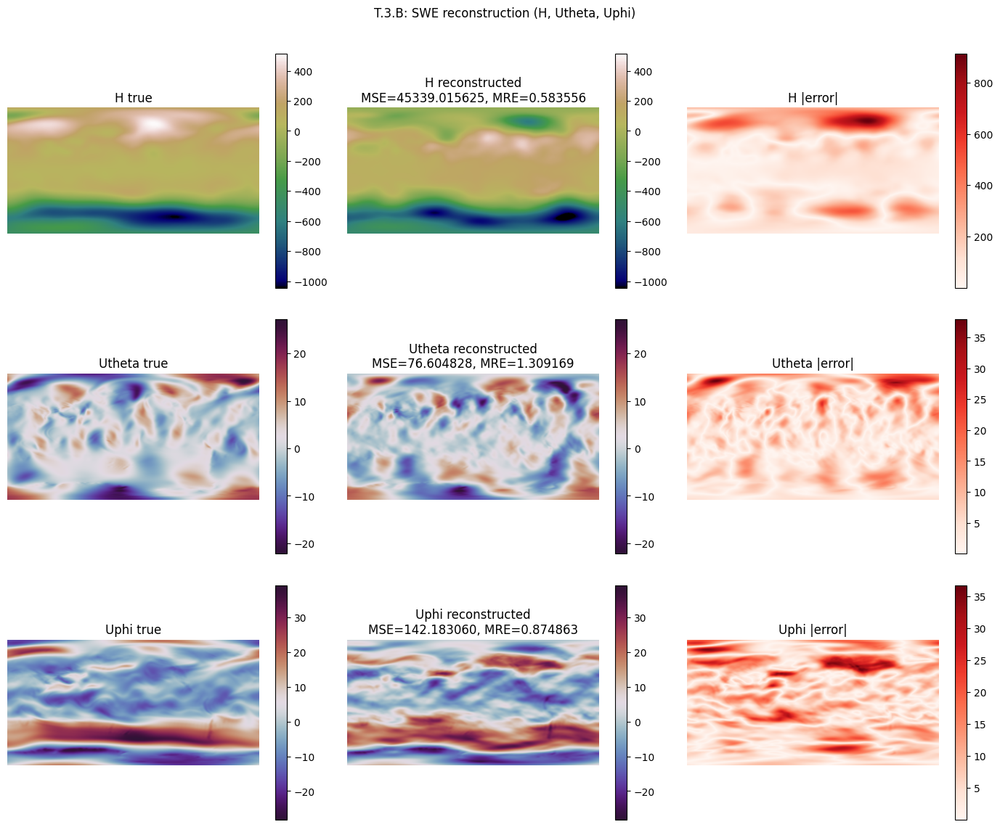

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
11,(mSHRED): transformer + MLP,(T.3.B) masking data x2 channels,0.02873,1.382389,2.898572,0.332402,0.898996,0.970591


In [ ]:
df_errors = run_experiment("T.3.B", "(T.3.B) masking data x2 channels", measurements, "transformer", masking_type="mask_data", double_channels=True)
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.3.C): Masking hidden space

Nuber of nan values in measurements after imputation: 649 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 649

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  41%|████▏     | 165/400 [00:46<01:06,  3.55it/s, Train Loss=0.01111, Val Loss=1.39392, Patience=99, Best Val Loss=1.37951, LR=6.32e-04]

Early stopping at epoch 166
Training completed with best validation loss: 1.3795


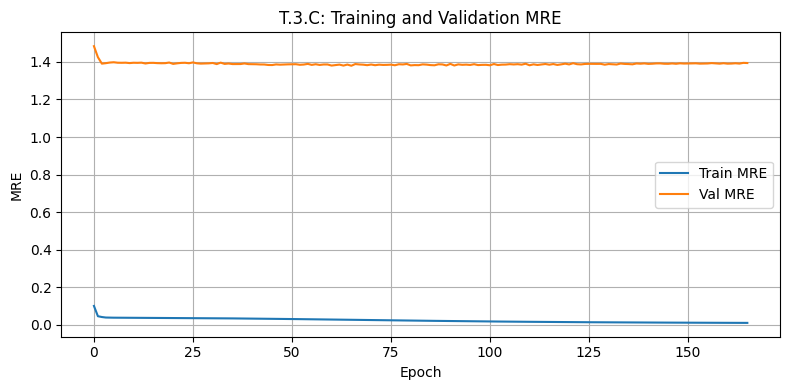

[T.3.C] test MRE: 0.96780

 ---------------------------------------------------------------------------------------------------- 



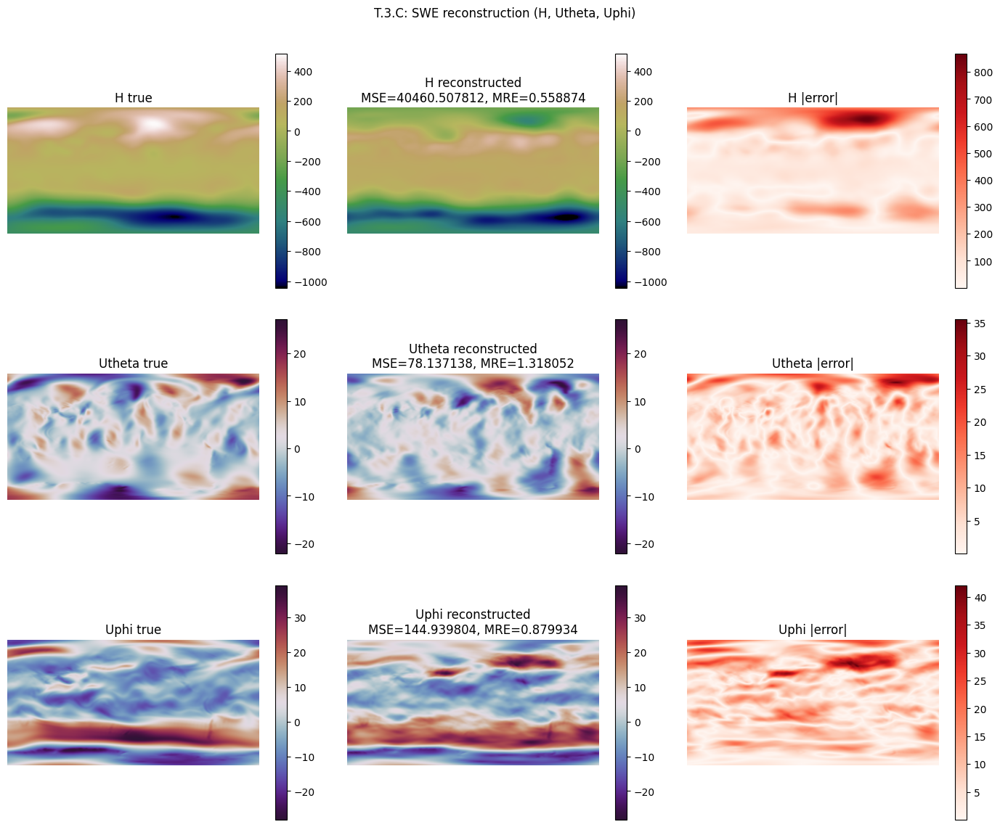

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
12,(mSHRED): transformer_hidden_mask + MLP,(T.3.C) masking hidden space,0.027382,1.37951,2.88844,0.324799,0.896573,0.967801


In [ ]:
df_errors = run_experiment("T.3.C", "(T.3.C) masking hidden space", measurements, "transformer_hidden_mask", masking_type="mask_data")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.3.D): Masking MHSA

Nuber of nan values in measurements after imputation: 649 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 649

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  26%|██▌       | 102/400 [00:43<02:06,  2.36it/s, Train Loss=0.01845, Val Loss=1.39656, Patience=99, Best Val Loss=1.38815, LR=8.45e-04]

Early stopping at epoch 103
Training completed with best validation loss: 1.3882


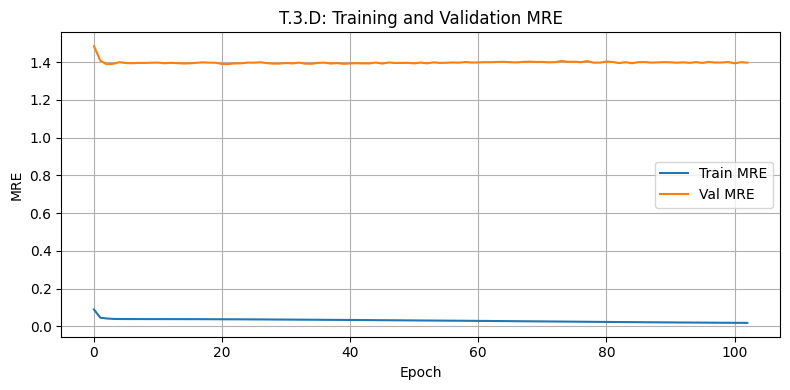

[T.3.D] test MRE: 0.96542

 ---------------------------------------------------------------------------------------------------- 



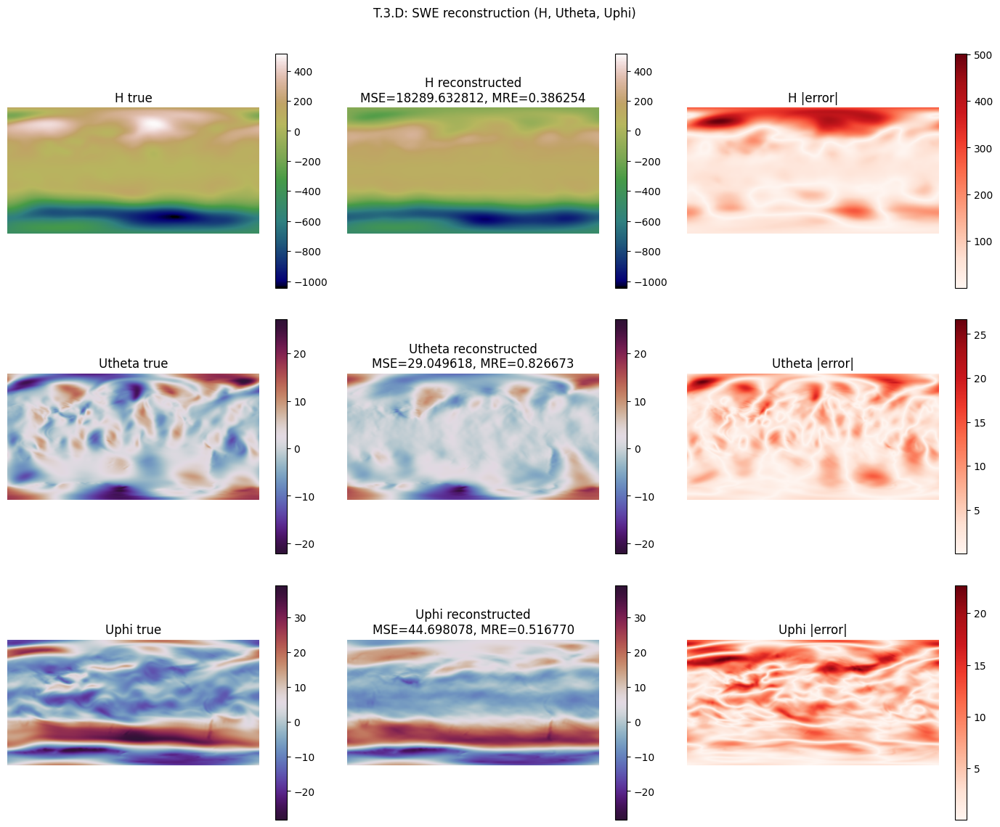

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
13,(mSHRED): transformer_attn_mask + MLP,(T.3.D) masking attention,0.041749,1.388154,2.864109,0.402256,0.901955,0.965424


In [ ]:
df_errors = run_experiment("T.3.D", "(T.3.D) masking attention", measurements, "transformer_attn_mask", masking_type="mask_data")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.3.E): Masking x2 channels + MHSA

Nuber of nan values in measurements after imputation: 649 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 649

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  25%|██▌       | 100/400 [00:25<01:16,  3.93it/s, Train Loss=0.01939, Val Loss=1.39835, Patience=99, Best Val Loss=1.35871, LR=8.51e-04]


Early stopping at epoch 101
Training completed with best validation loss: 1.3587


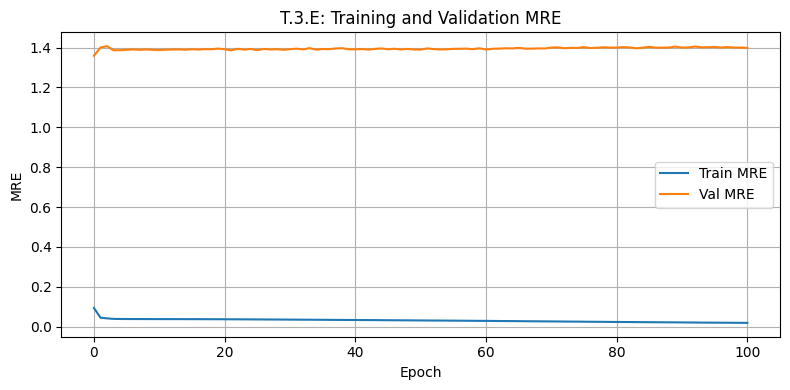

[T.3.E] test MRE: 0.95576

 ---------------------------------------------------------------------------------------------------- 



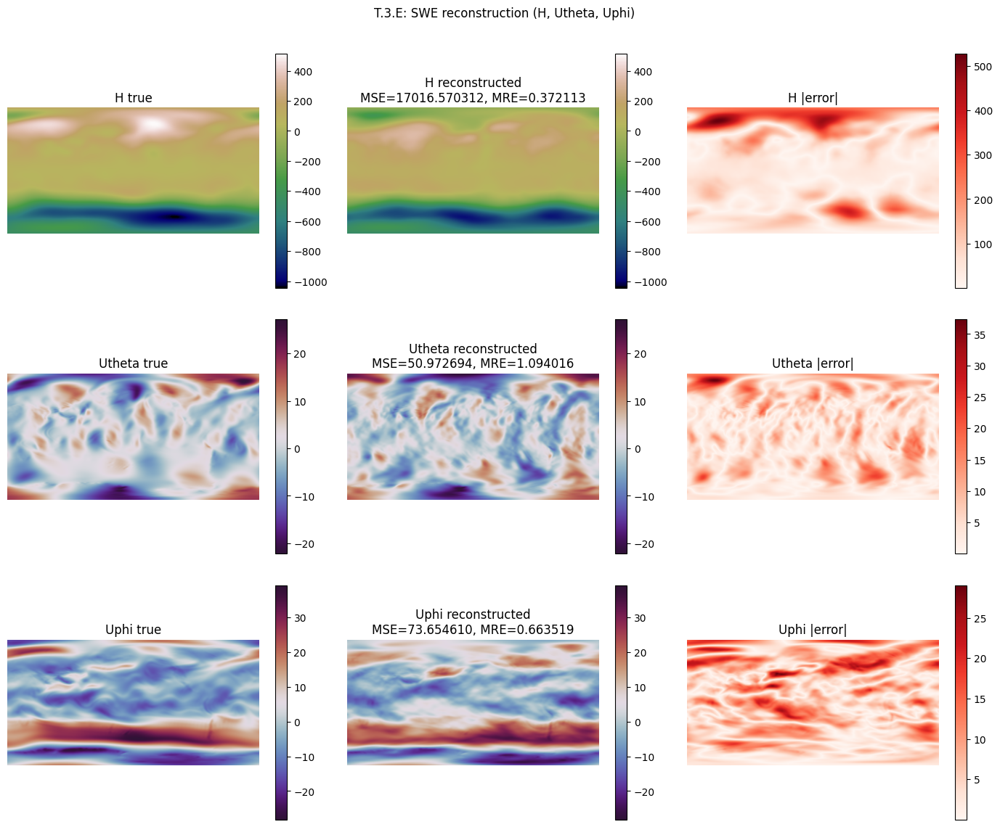

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
14,(mSHRED): transformer_attn_mask + MLP,(T.3.E) masking attention + x2 channels,0.094323,1.358711,2.79091,0.60532,0.903779,0.955757


In [ ]:
df_errors = run_experiment("T.3.E", "(T.3.E) masking attention + x2 channels", measurements, "transformer_attn_mask", masking_type="mask_data", double_channels=True)
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.3.F): Masking MHSA learned

Nuber of nan values in measurements after imputation: 649 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 649

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  76%|███████▌  | 302/400 [02:36<00:50,  1.93it/s, Train Loss=0.00749, Val Loss=1.38270, Patience=99, Best Val Loss=1.38052, LR=1.38e-04]

Early stopping at epoch 303
Training completed with best validation loss: 1.3805


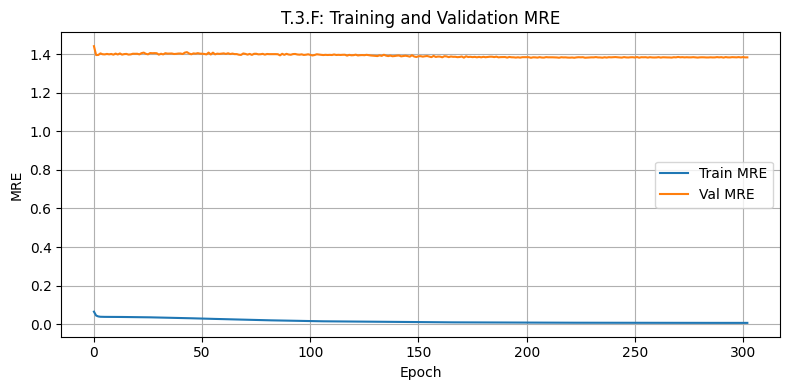

[T.3.F] test MRE: 0.97242

 ---------------------------------------------------------------------------------------------------- 



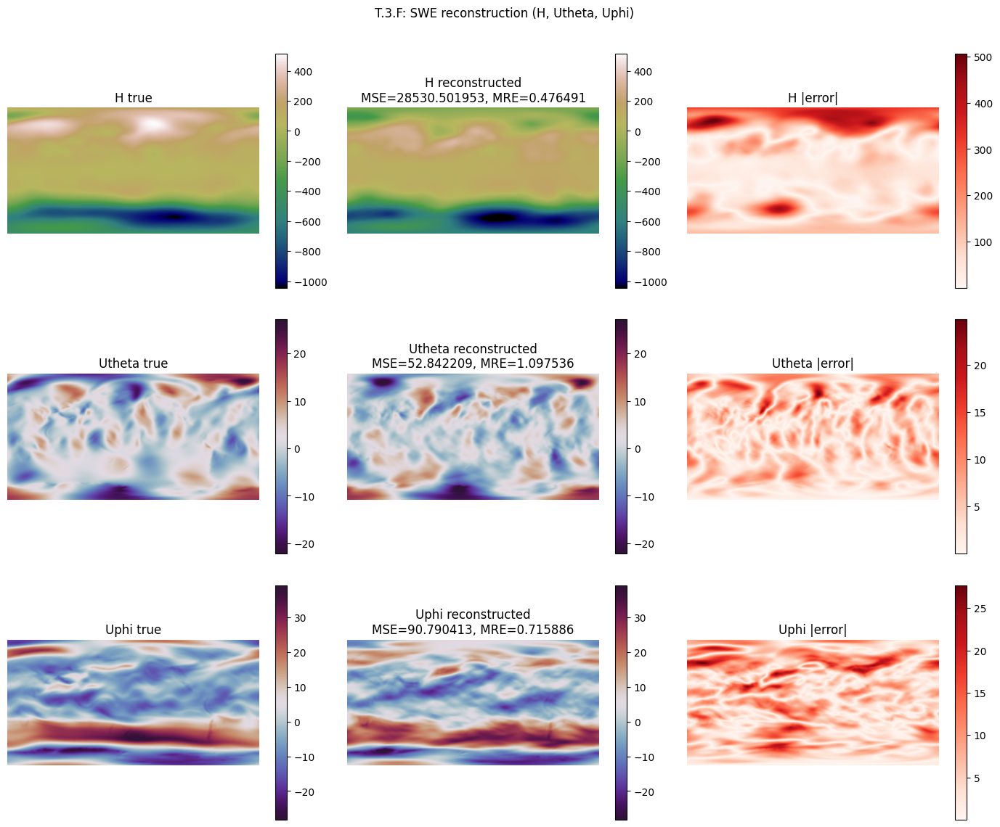

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
15,(mSHRED): transformer_learned_mask + MLP,(T.3.F) masking learned attention,0.008854,1.380523,2.956005,0.1839,0.891973,0.972419


In [ ]:
df_errors = run_experiment("T.3.F", "(T.3.F) masking learned attention", measurements, "transformer_learned_mask", masking_type="mask_data")
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## (T.3.G): Masking x2 channels + MHSA learned

Nuber of nan values in measurements after imputation: 649 

Residual energy of H after keeping 80 modes: 0.0395 %
Residual energy of Utheta after keeping 80 modes: 0.0993 %
Residual energy of Uphi after keeping 80 modes: 0.0593 %

Datasets: ['H', 'Utheta', 'Uphi']

Number of nan values in sensor measurements after masking: 649

Data shapes after preparation:
Train:	 torch.Size([806, 50, 3]) -> torch.Size([806, 240])
Val:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])
Test:	 torch.Size([101, 50, 3]) -> torch.Size([101, 240])

 ---------------------------------------------------------------------------------------------------- 

Starting training...


Training:  39%|███▉      | 157/400 [00:50<01:17,  3.14it/s, Train Loss=0.01190, Val Loss=1.40130, Patience=99, Best Val Loss=1.38430, LR=6.62e-04]

Early stopping at epoch 158
Training completed with best validation loss: 1.3843


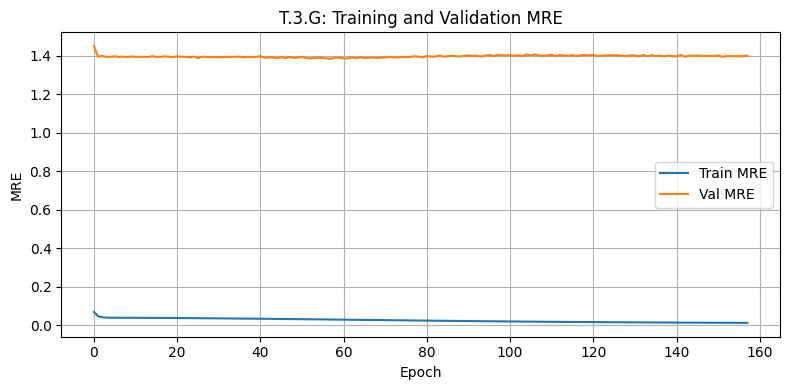

[T.3.G] test MRE: 0.96539

 ---------------------------------------------------------------------------------------------------- 



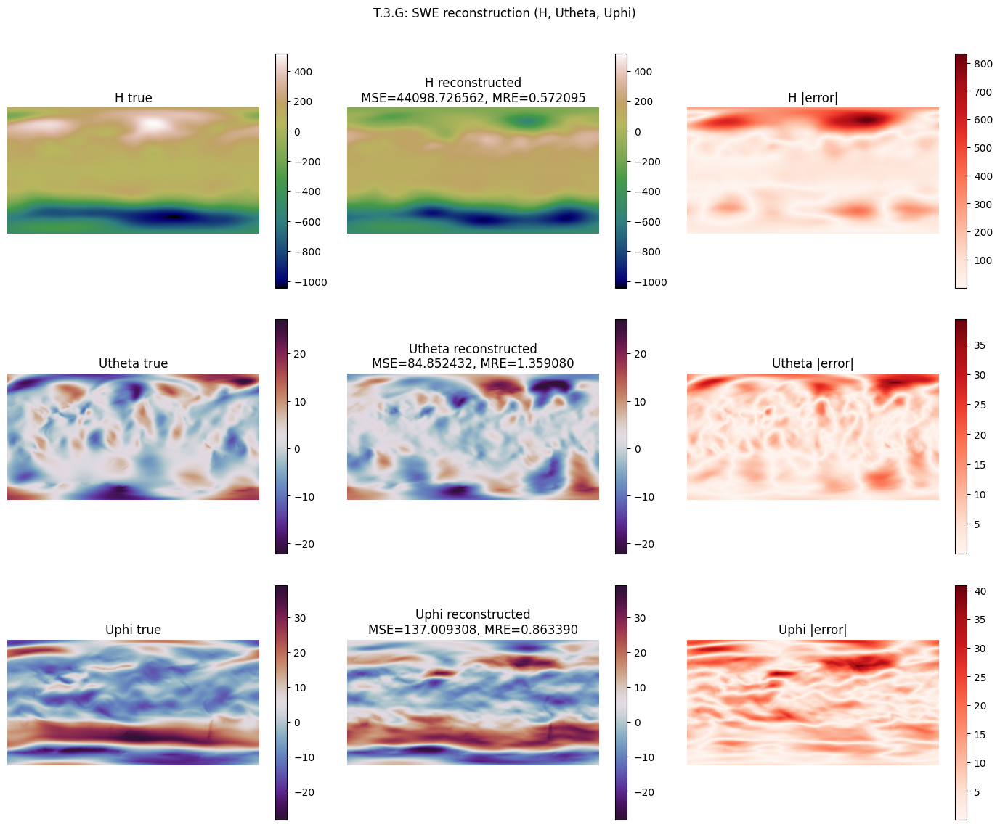

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
16,(mSHRED): transformer_attn_mask + MLP,(T.3.G) masking learned attention + x2 channels,0.029487,1.384304,2.839608,0.337338,0.896953,0.965395


In [ ]:
df_errors = run_experiment("T.3.G", "(T.3.G) masking learned attention + x2 channels", measurements, "transformer_attn_mask", masking_type="mask_data", double_channels=True)
display(df_errors.tail(1))
df_errors.to_csv("dataframe_errors.csv", index=False)

## Results

In [ ]:
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): transformer + MLP,(T.0) only available sensors,0.045276,1.396247,2.863958,0.418882,0.904218,0.963014
1,(mSHRED): lstm + MLP,(S.0) only available sensors,0.035580,1.397534,2.842296,0.370623,0.903067,0.963581
2,(mSHRED): transformer + MLP,(T.1.A) median imputer,0.031032,1.381489,2.854257,0.346627,0.897385,0.968088
3,(mSHRED): lstm + MLP,(S.1.A) median imputer,0.024276,1.388257,2.848928,0.304609,0.901830,0.966478
4,(mSHRED): transformer + MLP,(T.1.B) mean imputer,0.030449,1.389292,2.940617,0.343266,0.899182,0.976070
5,(mSHRED): lstm + MLP,(S.1.B) mean imputer,0.025283,1.381693,2.877826,0.312148,0.892225,0.955581
6,(mSHRED): transformer + MLP,(T.1.C) last value imputer,0.022390,1.402983,3.008563,0.293765,0.899032,0.982732
7,(mSHRED): lstm + MLP,(S.1.C) last value imputer,0.047366,1.390840,2.842760,0.428099,0.897367,0.955647
8,(mSHRED): grud + MLP,(T.2.A) GRUD encoder,0.032987,1.387630,2.828457,0.357032,0.899134,0.965392
9,(mSHRED): att_grud + MLP,(T.2.B) Attention GRUD encoder,0.033942,1.396450,2.909752,0.362277,0.901852,0.965653


In [ ]:
# ranking by test MRE
dataframe_errors = pd.DataFrame(ERRORS).sort_values(by="test-mre")
print("Final comparison ordered by test MRE:")
display(dataframe_errors)

Final comparison ordered by test MRE:


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
5,(mSHRED): lstm + MLP,(S.1.B) mean imputer,0.025283,1.381693,2.877826,0.312148,0.892225,0.955581
7,(mSHRED): lstm + MLP,(S.1.C) last value imputer,0.047366,1.390840,2.842760,0.428099,0.897367,0.955647
14,(mSHRED): transformer_attn_mask + MLP,(T.3.E) masking attention + x2 channels,0.094323,1.358711,2.790910,0.605320,0.903779,0.955757
0,(mSHRED): transformer + MLP,(T.0) only available sensors,0.045276,1.396247,2.863958,0.418882,0.904218,0.963014
1,(mSHRED): lstm + MLP,(S.0) only available sensors,0.035580,1.397534,2.842296,0.370623,0.903067,0.963581
10,(mSHRED): transformer + MLP,(T.3.A) masking data,0.039439,1.387496,2.856586,0.390973,0.902601,0.963833
8,(mSHRED): grud + MLP,(T.2.A) GRUD encoder,0.032987,1.387630,2.828457,0.357032,0.899134,0.965392
16,(mSHRED): transformer_attn_mask + MLP,(T.3.G) masking learned attention + x2 channels,0.029487,1.384304,2.839608,0.337338,0.896953,0.965395
13,(mSHRED): transformer_attn_mask + MLP,(T.3.D) masking attention,0.041749,1.388154,2.864109,0.402256,0.901955,0.965424
9,(mSHRED): att_grud + MLP,(T.2.B) Attention GRUD encoder,0.033942,1.396450,2.909752,0.362277,0.901852,0.965653


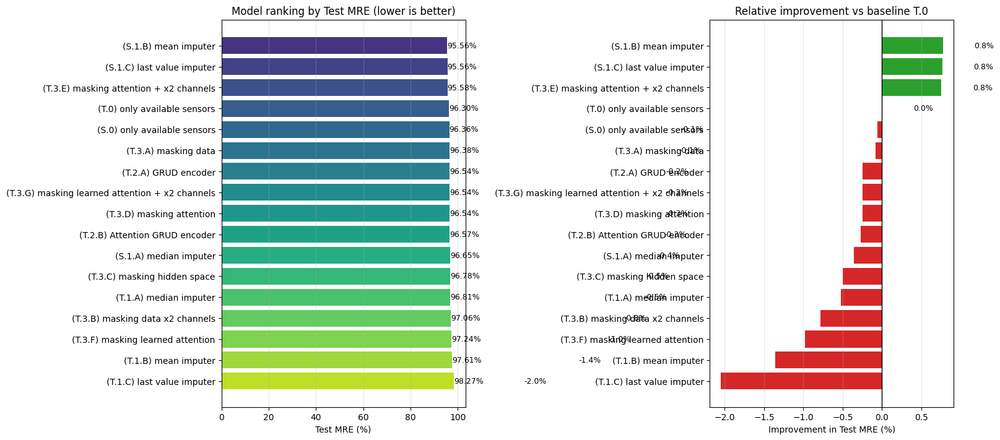

In [ ]:
# Meaningful summary plot: ranking + improvement vs baseline
df_plot = dataframe_errors.sort_values("test-mre").reset_index(drop=True)

# Baseline = T.0 (only available sensors)
baseline_mask = df_plot["type"].str.contains("T.0", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(df_plot)))
axes[0].barh(df_plot["type"], df_plot["test-mre_%"], color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=9)

# --- Right: Improvement vs baseline (T.0) ---
imp_colors = ["tab:green" if x >= 0 else "tab:red" for x in df_plot["improvement_vs_T0_%"]]
axes[1].barh(df_plot["type"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline T.0")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(v + (0.4 if v >= 0 else -2.5), i, f"{v:.1f}%", va="center", fontsize=9)

plt.show()